# Bayesian decisions: when is another inspection worth taking?

**Notebook author: Ziad Mosalam**  
Companion to *Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems* by Khalid M. Mosalam.

The **Bayesian Decision Theory for Engineering Systems** chapter separates inference from action. Here we make that distinction concrete: the same inspection result may justify continuing operation, repairing, or replacing a component, depending on what each action costs.

This is a synthetic one-decision model, not a maintenance recommendation. Every probability, cost and action effect below is an explicit modeling assumption. It complements the chapter's inspection-and-renewal example; it does not replace its long-run cost model.

Run all cells from the `notebooks/` directory. The final figure appears here and is exported to `../figures/bayesian-decisions.pdf` and `.png`.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.special import ndtr
from scipy.stats import norm

plt.style.use('book.mplstyle')
figures = Path('../figures')
figures.mkdir(exist_ok=True)

BLUE, GOLD, TEAL, INK = '#003262', '#B17A00', '#247C86', '#30363B'
action_names = ['Continue', 'Repair', 'Replace']
action_colors = [TEAL, GOLD, BLUE]

## 1. State, observation and consequences

Let $X$ be a standardized latent condition index. Larger values indicate worse condition; the index is dimensionless and has no physical damage threshold attached to it. Before the new inspection,
\[
X\sim\mathcal N(0,1),\qquad Y=X+\epsilon,\qquad \epsilon\sim\mathcal N(0,\sigma^2).
\]
The observation noise is independent of $X$. Its standard deviation $\sigma$ measures inspection imprecision in the same index units.

Conditional failure probability over one fixed decision horizon is assumed to be
\[
p_f(x)=\Phi\!\left(\frac{x-b}{s_f}\right),
\]
where $\Phi$ is the standard normal CDF. Failure remains random even if $X$ is known. Set $b=1$ and $s_f=0.45$.

The three actions have the following conditional expected losses, in arbitrary cost units:

| Action | Conditional expected loss | Assumption |
|---|---|---|
| Continue | $100\,p_f(x)$ | No immediate intervention cost |
| Repair | $5+100\,p_f(x-0.7)$ | A known, deterministic improvement of 0.7 index units |
| Replace | $18$ | Replacement prevents the modeled failure within this horizon |

These action effects are deliberately transparent. A real analysis would need evidence for failure consequences, repair effectiveness, replacement risk and the time horizon.

In [2]:
prior_mean, prior_variance = 0.0, 1.0
failure_cost, repair_cost, replacement_cost = 100.0, 5.0, 18.0
failure_threshold, failure_spread, repair_shift = 1.0, 0.45, 0.7

def posterior_parameters(observation, noise_sd):
    """Gaussian conditioning, including the noiseless observation limit."""
    gain = prior_variance / (prior_variance + noise_sd**2)
    mean = prior_mean + gain * (np.asarray(observation) - prior_mean)
    variance = prior_variance * noise_sd**2 / (prior_variance + noise_sd**2)
    return mean, variance

def expected_losses(mean, variance):
    """Expected loss of each action under X ~ Normal(mean, variance)."""
    mean = np.asarray(mean)
    spread = np.sqrt(failure_spread**2 + variance)
    continue_loss = failure_cost * ndtr((mean - failure_threshold) / spread)
    repair_loss = repair_cost + failure_cost * ndtr(
        (mean - repair_shift - failure_threshold) / spread
    )
    replace_loss = np.full_like(mean, replacement_cost, dtype=float)
    return np.array([continue_loss, repair_loss, replace_loss])

def posterior_losses(observation, noise_sd):
    mean, variance = posterior_parameters(observation, noise_sd)
    return expected_losses(mean, variance)

prior_losses = expected_losses(prior_mean, prior_variance)
prior_action = int(np.argmin(prior_losses))
prior_risk = float(prior_losses[prior_action])

for name, loss in zip(action_names, prior_losses):
    print(f'{name:8s}: expected loss = {loss:.3f}')
print(f'Without a new observation: {action_names[prior_action]}.')

Continue: expected loss = 18.091
Repair  : expected loss = 11.054
Replace : expected loss = 18.000
Without a new observation: Repair.


## 2. Posterior risk has an analytic expression

For a Gaussian posterior $X\mid y\sim\mathcal N(\mu_y,v_y)$,
\[
\mu_y=\frac{y}{1+\sigma^2},\qquad
v_y=\frac{\sigma^2}{1+\sigma^2}.
\]
To average the failure model over this posterior, introduce an independent standard normal $Z$. Then
\[
\mathbb E\!\left[\Phi\!\left(\frac{X-b}{s_f}\right)\middle|y\right]
=\Pr(s_f Z\le X-b\mid y)
=\Phi\!\left(\frac{\mu_y-b}{\sqrt{s_f^2+v_y}}\right).
\]
The repair action uses the same expression with $b$ replaced by $b+0.7$. We therefore integrate the entire posterior analytically, rather than substitute a point estimate into a nonlinear failure model.

The Bayes action minimizes these three posterior expected losses. An action boundary is a cost comparison, not an independently prescribed failure-probability threshold.

In [3]:
noise_sd = 0.55
observations = np.linspace(-3.2, 3.2, 501)
loss_curves = posterior_losses(observations, noise_sd)
best_action = np.argmin(loss_curves, axis=0)

def action_boundaries(noise_sd):
    """Locate changes in the lowest-risk action on a broad observation interval."""
    observation_sd = np.sqrt(prior_variance + noise_sd**2)
    grid = prior_mean + observation_sd * np.linspace(-10, 10, 801)
    decisions = np.argmin(posterior_losses(grid, noise_sd), axis=0)
    changes = np.flatnonzero(np.diff(decisions))
    boundaries = []
    for index in changes:
        left_action, right_action = decisions[index:index + 2]
        boundary = brentq(
            lambda y: posterior_losses(y, noise_sd)[left_action]
            - posterior_losses(y, noise_sd)[right_action],
            grid[index], grid[index + 1],
        )
        boundaries.append(boundary)
    return np.array(boundaries)

boundaries = action_boundaries(noise_sd)
print(f'For inspection noise SD {noise_sd:.2f}:')
print('Action boundaries at observed index:', np.round(boundaries, 3))
for y in [-1.0, 1.0, 2.0]:
    losses = posterior_losses(y, noise_sd)
    mean, variance = posterior_parameters(y, noise_sd)
    print(f'y = {y:4.1f}: posterior mean = {mean:5.2f}, '
          f'SD = {np.sqrt(variance):.2f}; choose {action_names[np.argmin(losses)]}.')

For inspection noise SD 0.55:
Action boundaries at observed index: [-0.08   1.247]
y = -1.0: posterior mean = -0.77, SD = 0.48; choose Continue.
y =  1.0: posterior mean =  0.77, SD = 0.48; choose Repair.
y =  2.0: posterior mean =  1.54, SD = 0.48; choose Replace.


## 3. Value of information is evaluated before seeing the inspection

The predictive observation distribution is $Y\sim\mathcal N(0,1+\sigma^2)$. The expected value of sample information is
\[
\operatorname{EVSI}(\sigma)
=\min_a\mathbb E[L(X,a)]
-\mathbb E_Y\!\left[\min_a\mathbb E[L(X,a)\mid Y]\right].
\]
The order matters: choose the action **after** the observation inside the second expectation. This expected benefit excludes the cost of taking the inspection. If inspection costs 2 units, inspect only when EVSI exceeds 2 under this model.

Numerical quadrature integrates over a standard normal variable. We split the integral at action switches to handle the kinks in the minimum-risk curve. Truncating at 10 standard deviations omits negligible Gaussian mass; all conditional losses are bounded by 105 units.

At $\sigma=0$, the observation reveals $X$ exactly. This gives the expected value of perfect **state** information, EVPI. It does not reveal whether a future random failure will occur.

In [4]:
def risk_with_inspection(noise_sd):
    observation_sd = np.sqrt(prior_variance + noise_sd**2)
    standardized_switches = (
        action_boundaries(noise_sd) - prior_mean
    ) / observation_sd

    def integrand(z):
        y = prior_mean + observation_sd * z
        return np.min(posterior_losses(y, noise_sd)) * norm.pdf(z)

    risk, integration_error = quad(
        integrand, -10, 10, points=standardized_switches,
        epsabs=1e-9, epsrel=1e-9, limit=150,
    )
    return risk, integration_error

noise_grid = np.linspace(0, 4, 101)
preposterior_risk = np.array([risk_with_inspection(sd)[0] for sd in noise_grid])
evsi = prior_risk - preposterior_risk
evpi = float(evsi[0])
inspection_cost = 2.0
noise_break_even = brentq(
    lambda sd: prior_risk - risk_with_inspection(sd)[0] - inspection_cost, 0, 4
)
print(f'EVPI of the state: {evpi:.3f} cost units')
print(f'EVSI at SD {noise_sd}: {prior_risk - risk_with_inspection(noise_sd)[0]:.3f}')
print(f'Break-even inspection SD for cost {inspection_cost:g}: {noise_break_even:.3f}')

EVPI of the state: 6.478 cost units
EVSI at SD 0.55: 4.618
Break-even inspection SD for cost 2: 1.239


## 4. Checks on the decision calculation

The law of total expectation requires the average posterior loss of a **fixed** action to equal its prior loss. Information can improve the action choice, but it cannot improve the expected loss of a fixed action. We also check the perfect/no-information limits and the ordering $0\le\operatorname{EVSI}\le\operatorname{EVPI}$.

In [5]:
# Independently integrate over the latent state to check the analytic probit average.
for y in [-1.0, 1.0, 2.0]:
    mean, variance = posterior_parameters(y, noise_sd)
    numerical_losses = []
    for shift, immediate_cost in [(0.0, 0.0), (repair_shift, repair_cost)]:
        failure_probability = quad(
            lambda x: ndtr((x - shift - failure_threshold) / failure_spread)
            * norm.pdf(x, mean, np.sqrt(variance)),
            -np.inf, np.inf, epsabs=1e-10,
        )[0]
        numerical_losses.append(immediate_cost + failure_cost * failure_probability)
    np.testing.assert_allclose(numerical_losses, posterior_losses(y, noise_sd)[:2], atol=1e-8)

for sd in [0.0, 0.55, 2.0]:
    observation_sd = np.sqrt(prior_variance + sd**2)
    average_fixed_losses = np.array([
        quad(lambda z: posterior_losses(observation_sd * z, sd)[a] * norm.pdf(z),
             -10, 10, epsabs=1e-9)[0]
        for a in range(3)
    ])
    np.testing.assert_allclose(average_fixed_losses, prior_losses, atol=1e-8)

assert np.all(evsi >= -1e-8)
assert np.all(evsi <= evpi + 1e-8)
assert np.all(np.diff(evsi) <= 1e-7)  # More independent Gaussian noise cannot add information.
np.testing.assert_allclose(risk_with_inspection(1e6)[0], prior_risk, atol=1e-8)
assert risk_with_inspection(noise_sd)[1] < 1e-7
print('Posterior loss integrals, fixed-action expectation, information bounds and limits passed.')

Posterior loss integrals, fixed-action expectation, information bounds and limits passed.


## 5. Read the figure from uncertainty to action

The top row shows how a new observation changes the condition distribution and the expected losses. The lower-left map repeats the action calculation for different inspection precisions. As the observation becomes noisy, increasingly extreme values are needed to overturn the prior preference for repair. The lower-right panel asks whether obtaining the observation is worth its cost **before it is known**.

Colors identify actions consistently: teal for continue, gold for repair, and blue for replace. The three posterior densities are colored by the optimal action for that observation. They are selected examples, not three different data-generating models.

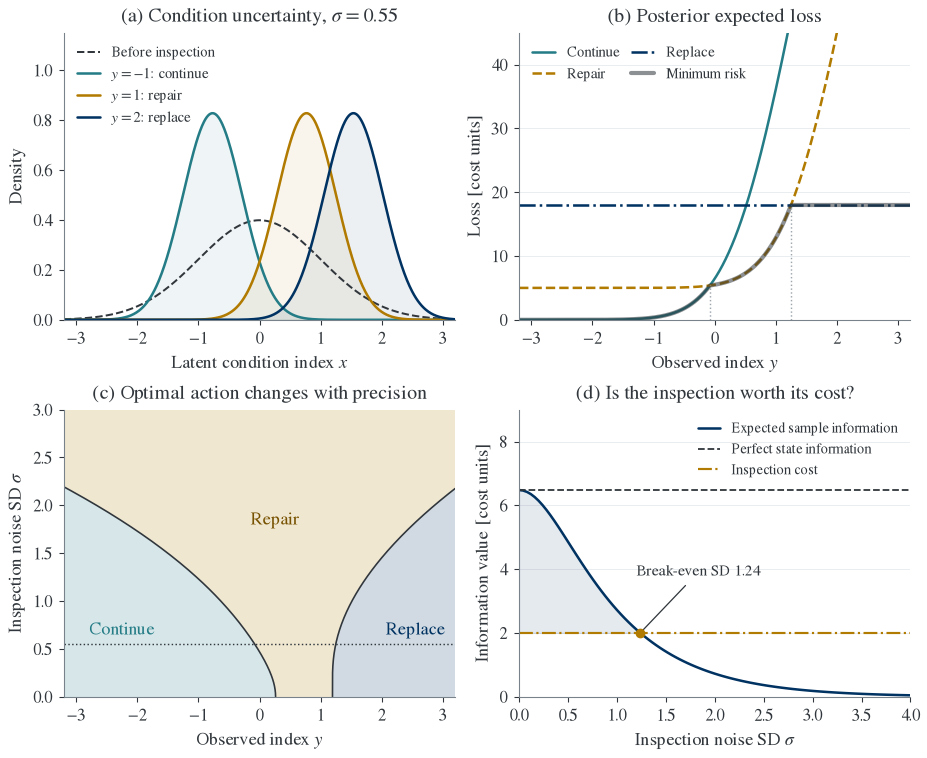

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(7.1, 5.8), layout='constrained')

ax = axes[0, 0]
state_grid = np.linspace(-3.2, 3.2, 601)
ax.plot(state_grid, norm.pdf(state_grid), color=INK, ls='--', lw=1.1, label='Before inspection')
for y in [-1.0, 1.0, 2.0]:
    mean, variance = posterior_parameters(y, noise_sd)
    action = int(np.argmin(posterior_losses(y, noise_sd)))
    density = norm.pdf(state_grid, mean, np.sqrt(variance))
    ax.plot(state_grid, density, color=action_colors[action], label=fr'$y={y:g}$: {action_names[action].lower()}')
    ax.fill_between(state_grid, density, color=action_colors[action], alpha=0.07)
ax.set(title=r'(a) Condition uncertainty, $\sigma=0.55$', xlabel='Latent condition index $x$', ylabel='Density')
ax.set_xlim(-3.2, 3.2)
ax.set_ylim(0, 1.15)
ax.legend(loc='upper left', fontsize=8, handlelength=1.6)

ax = axes[0, 1]
for action in range(3):
    ax.plot(observations, loss_curves[action], color=action_colors[action],
            ls=['-', '--', '-.'][action], label=action_names[action])
ax.plot(observations, loss_curves.min(axis=0), color=INK, lw=2.3, alpha=0.55, label='Minimum risk')
for boundary in boundaries:
    ax.vlines(boundary, 0, np.min(posterior_losses(boundary, noise_sd)),
              color='#9EA6AD', ls=':', lw=0.8)
ax.set(title='(b) Posterior expected loss', xlabel='Observed index $y$', ylabel='Loss [cost units]',
       xlim=(-3.2, 3.2), ylim=(0, 45))
ax.legend(fontsize=8, loc='upper left', ncol=2, columnspacing=0.8, handlelength=1.6)
ax.grid(axis='y', alpha=0.7)

ax = axes[1, 0]
map_noise = np.linspace(0, 3.0, 241)
map_y = np.linspace(-3.2, 3.2, 401)
policy = np.array([np.argmin(posterior_losses(map_y, sd), axis=0) for sd in map_noise])
ax.pcolormesh(map_y, map_noise, policy, cmap=ListedColormap(action_colors),
              vmin=-0.5, vmax=2.5, shading='nearest', alpha=0.18, rasterized=True)
for action in range(2):
    transition_y = []
    transition_sd = []
    for sd in map_noise:
        roots = action_boundaries(sd)
        if len(roots) == 2 and -3.2 <= roots[action] <= 3.2:
            transition_y.append(roots[action])
            transition_sd.append(sd)
    ax.plot(transition_y, transition_sd, color=INK, lw=0.9)
ax.axhline(noise_sd, color=INK, ls=':', lw=0.8)
ax.text(-2.25, 0.65, 'Continue', color=TEAL, ha='center', fontsize=10)
ax.text(0.25, 1.8, 'Repair', color='#775200', ha='center', fontsize=10)
ax.text(2.55, 0.65, 'Replace', color=BLUE, ha='center', fontsize=10)
ax.set(title='(c) Optimal action changes with precision', xlabel='Observed index $y$',
       ylabel=r'Inspection noise SD $\sigma$', xlim=(-3.2, 3.2), ylim=(0, 3))

ax = axes[1, 1]
ax.plot(noise_grid, evsi, color=BLUE, label='Expected sample information')
ax.axhline(evpi, color=INK, ls='--', lw=1, label='Perfect state information')
ax.axhline(inspection_cost, color=GOLD, ls='-.', lw=1.2, label='Inspection cost')
ax.fill_between(noise_grid, inspection_cost, evsi, where=evsi >= inspection_cost,
                 interpolate=True, color=BLUE, alpha=0.1)
ax.scatter([noise_break_even], [inspection_cost], color=GOLD, s=22, zorder=5)
ax.annotate(f'Break-even SD {noise_break_even:.2f}', xy=(noise_break_even, inspection_cost),
            xytext=(1.2, 3.8), fontsize=8.5,
            arrowprops=dict(arrowstyle='-', color=INK, lw=0.7))
ax.set(title='(d) Is the inspection worth its cost?', xlabel=r'Inspection noise SD $\sigma$',
       ylabel='Information value [cost units]', xlim=(0, 4), ylim=(0, 9))
ax.set_yticks([0, 2, 4, 6, 8])
ax.legend(loc='upper right', fontsize=7.7, handlelength=1.6)
ax.grid(axis='y', alpha=0.7)

fig.savefig(figures / 'bayesian-decisions.pdf')
fig.savefig(figures / 'bayesian-decisions.png', dpi=240)
plt.show()

## What this example establishes, and what it does not

An informative observation can change the optimal action. Its expected value depends on the loss model and on whether the observation is precise enough to change that action. More precise inspection is beneficial here because we hold all other assumptions fixed and allow the decision maker to ignore information.

This model assumes a known observation error, a known failure link, perfectly specified repair effectiveness, and replacement that eliminates the modeled failure during one horizon. It omits repeated decisions, discounting, imperfect execution and uncertainty in model parameters. Those omissions are why the numerical action boundaries and inspection value should not be used as field recommendations.